In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib
import warnings
warnings.filterwarnings("ignore")

from sklearn.metrics import (precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, confusion_matrix, ConfusionMatrixDisplay)
from sklearn.model_selection import ParameterSampler
from xgboost import XGBClassifier

df = pd.read_csv("../data/flood_features.csv", parse_dates=["timestamp"])

targets = [c for c in df.columns if c.startswith(("flood_next", "onset_next"))]
drop_cols = ["timestamp", "station_id", "station_name", "district", "river",
             "latitude", "longitude", "month", "hour", "wind_direction_deg",
             "water_level_m", "danger_level_m",
             "flood_occurred", "flood_severity", "flood_extent_km2"]
features = [c for c in df.columns if c not in drop_cols + targets]

TARGET = "onset_next_24h"
print("Features:", len(features))

Features: 52


In [2]:
train = df[df["timestamp"] < "2023-12-29"]
val   = df[(df["timestamp"] >= "2024-01-01") & (df["timestamp"] < "2024-06-28")]
test  = df[df["timestamp"] >= "2024-07-01"]

X_train, X_val, X_test = train[features], val[features], test[features]
y_train, y_val, y_test = train[TARGET], val[TARGET], test[TARGET]

ratio = (y_train == 0).sum() / (y_train == 1).sum()
print("Train:", X_train.shape, "| Val:", X_val.shape, "| Test:", X_test.shape)
print("No-onset : onset ratio in train =", round(ratio, 1))

Train: (42600, 52) | Val: (21480, 52) | Test: (21720, 52)
No-onset : onset ratio in train = 62.6


In [3]:
def best_threshold(y_true, prob):
    best_t, best_f1 = 0.5, -1
    for t in np.arange(0.01, 1.00, 0.01):
        f1 = f1_score(y_true, (prob >= t).astype(int), zero_division=0)
        if f1 > best_f1:
            best_t, best_f1 = t, f1
    return best_t

def show_scores(name, prob_test, t):
    pred = (prob_test >= t).astype(int)
    print(f"--- {name} (threshold = {t:.2f}) ---")
    print("Precision:", round(precision_score(y_test, pred), 3))
    print("Recall   :", round(recall_score(y_test, pred), 3))
    print("F1       :", round(f1_score(y_test, pred), 3))
    print("ROC-AUC  :", round(roc_auc_score(y_test, prob_test), 3))
    print("PR-AUC   :", round(average_precision_score(y_test, prob_test), 3))
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=["No", "Yes"]).plot(cmap="Blues")
    plt.title(name)
    plt.show()
    

--- XGBoost (default) (threshold = 0.01) ---
Precision: 0.241
Recall   : 0.706
F1       : 0.36
ROC-AUC  : 0.973
PR-AUC   : 0.503


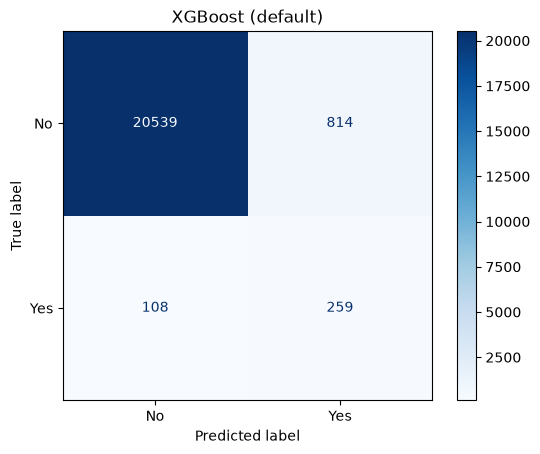

In [4]:
xgb_default = XGBClassifier(n_estimators=400, max_depth=6, learning_rate=0.05,
                            subsample=0.8, colsample_bytree=0.8, scale_pos_weight=ratio,
                            eval_metric="logloss", n_jobs=-1, random_state=42)
xgb_default.fit(X_train, y_train)

t_default = best_threshold(y_val, xgb_default.predict_proba(X_val)[:, 1])
show_scores("XGBoost (default)", xgb_default.predict_proba(X_test)[:, 1], t_default)

In [5]:
param_grid = {
    "n_estimators":     [200, 400, 800],
    "max_depth":        [3, 4, 5, 6, 8],
    "learning_rate":    [0.01, 0.03, 0.05, 0.1],
    "min_child_weight": [1, 5, 10],
    "subsample":        [0.7, 0.8, 1.0],
    "colsample_bytree": [0.5, 0.7, 0.9],
    "scale_pos_weight": [1, round(np.sqrt(ratio), 1), round(ratio, 1)],
}

combos = list(ParameterSampler(param_grid, n_iter=30, random_state=42))
rows = []
for i, params in enumerate(combos, 1):
    model = XGBClassifier(**params, eval_metric="logloss", n_jobs=-1, random_state=42)
    model.fit(X_train, y_train)
    prob_val = model.predict_proba(X_val)[:, 1]
    rows.append({**params, "val_PR_AUC": average_precision_score(y_val, prob_val)})
    print(f"{i}/30 done | val PR-AUC = {rows[-1]['val_PR_AUC']:.3f}")

tuning = pd.DataFrame(rows).sort_values("val_PR_AUC", ascending=False).reset_index(drop=True)
tuning.head(10)

1/30 done | val PR-AUC = 0.528
2/30 done | val PR-AUC = 0.532
3/30 done | val PR-AUC = 0.519
4/30 done | val PR-AUC = 0.607
5/30 done | val PR-AUC = 0.519
6/30 done | val PR-AUC = 0.607
7/30 done | val PR-AUC = 0.530
8/30 done | val PR-AUC = 0.564
9/30 done | val PR-AUC = 0.580
10/30 done | val PR-AUC = 0.591
11/30 done | val PR-AUC = 0.533
12/30 done | val PR-AUC = 0.558
13/30 done | val PR-AUC = 0.578
14/30 done | val PR-AUC = 0.543
15/30 done | val PR-AUC = 0.548
16/30 done | val PR-AUC = 0.580
17/30 done | val PR-AUC = 0.526
18/30 done | val PR-AUC = 0.551
19/30 done | val PR-AUC = 0.522
20/30 done | val PR-AUC = 0.564
21/30 done | val PR-AUC = 0.544
22/30 done | val PR-AUC = 0.536
23/30 done | val PR-AUC = 0.529
24/30 done | val PR-AUC = 0.527
25/30 done | val PR-AUC = 0.565
26/30 done | val PR-AUC = 0.580
27/30 done | val PR-AUC = 0.559
28/30 done | val PR-AUC = 0.549
29/30 done | val PR-AUC = 0.549
30/30 done | val PR-AUC = 0.530


,subsample,scale_pos_weight,n_estimators,min_child_weight,max_depth,learning_rate,colsample_bytree,val_PR_AUC
0,0.8,62.6,200,10,3,0.03,0.5,0.607263
1,0.7,62.6,400,5,5,0.01,0.9,0.607058
2,1.0,1.0,400,10,3,0.01,0.7,0.591196
3,0.7,62.6,800,1,5,0.01,0.7,0.580212
4,0.8,7.9,800,5,4,0.01,0.5,0.580060
5,0.8,1.0,400,10,4,0.01,0.9,0.579834
6,0.7,7.9,200,1,3,0.05,0.7,0.578470
7,0.7,7.9,200,1,5,0.05,0.5,0.565491
8,0.7,7.9,200,1,4,0.10,0.7,0.564291
9,0.7,62.6,400,10,3,0.03,0.5,0.564082


In [6]:
best_params = tuning.iloc[0].drop("val_PR_AUC").to_dict()
for k in ["n_estimators", "max_depth", "min_child_weight"]:
    best_params[k] = int(best_params[k])
print(best_params)

{'subsample': 0.8, 'scale_pos_weight': 62.6, 'n_estimators': 200, 'min_child_weight': 10, 'max_depth': 3, 'learning_rate': 0.03, 'colsample_bytree': 0.5}


--- XGBoost (tuned) (threshold = 0.26) ---
Precision: 0.232
Recall   : 0.768
F1       : 0.356
ROC-AUC  : 0.978
PR-AUC   : 0.524


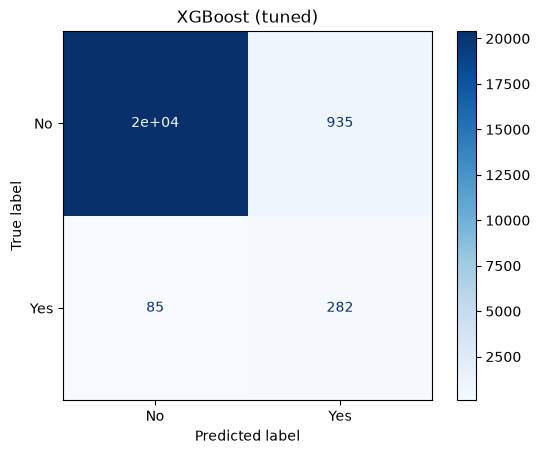

In [7]:
xgb_tuned = XGBClassifier(**best_params, eval_metric="logloss", n_jobs=-1, random_state=42)
xgb_tuned.fit(X_train, y_train)

t_tuned = best_threshold(y_val, xgb_tuned.predict_proba(X_val)[:, 1])
prob_test = xgb_tuned.predict_proba(X_test)[:, 1]
show_scores("XGBoost (tuned)", prob_test, t_tuned)

In [8]:
compare = []
for name, model, t in [("Default", xgb_default, t_default), ("Tuned", xgb_tuned, t_tuned)]:
    p = model.predict_proba(X_test)[:, 1]
    pred = (p >= t).astype(int)
    compare.append({"XGBoost": name, "Threshold": round(t, 2),
                    "Precision": precision_score(y_test, pred), "Recall": recall_score(y_test, pred),
                    "F1": f1_score(y_test, pred), "ROC-AUC": roc_auc_score(y_test, p),
                    "PR-AUC": average_precision_score(y_test, p)})
pd.DataFrame(compare).round(3)

,XGBoost,Threshold,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Default,0.01,0.241,0.706,0.360,0.973,0.503
1,Tuned,0.26,0.232,0.768,0.356,0.978,0.524


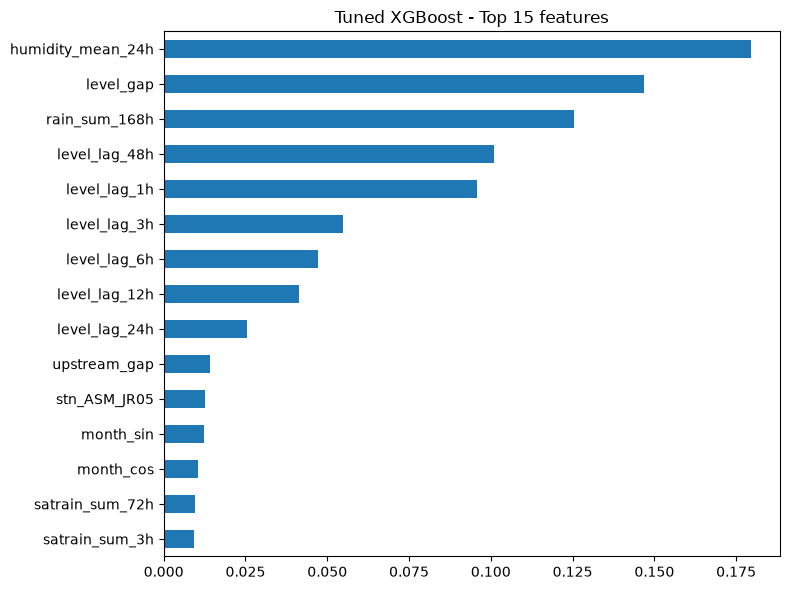

In [9]:
imp = pd.Series(xgb_tuned.feature_importances_, index=features).sort_values(ascending=False).head(15)
imp.sort_values().plot(kind="barh", figsize=(8, 6), title="Tuned XGBoost - Top 15 features")
plt.tight_layout()
plt.show()


In [10]:
res = test[["timestamp", "station_id", "level_gap", "flood_occurred", TARGET]].copy()
res["probability"] = prob_test

def status(row):
    if row["level_gap"] >= 0:
        return "Flood ongoing"
    if row["probability"] >= t_tuned:
        return "High"
    if row["probability"] >= 0.3:
        return "Medium"
    return "Low"

res["status"] = res.apply(status, axis=1)
res.groupby("status")[TARGET].agg(["count", "mean"]).round(3)

,count,mean
status,,
Flood ongoing,6979,0.000
High,1176,0.240
Low,13565,0.006


In [11]:
res = res.sort_values(["station_id", "timestamp"])
res["flood_start"] = res.groupby("station_id")["flood_occurred"].diff() == 1
events = res[res["flood_start"]]

caught = 0
for _, ev in events.iterrows():
    before = res[(res["station_id"] == ev["station_id"]) &
                 (res["timestamp"] < ev["timestamp"]) &
                 (res["timestamp"] >= ev["timestamp"] - pd.Timedelta(hours=24))]
    if (before["probability"] >= t_tuned).any():
        caught += 1

print(f"Flood starts in test period: {len(events)}")
print(f"Warned in advance (within 24h): {caught}  ->  {caught/len(events)*100:.0f}%")

Flood starts in test period: 25
Warned in advance (within 24h): 24  ->  96%


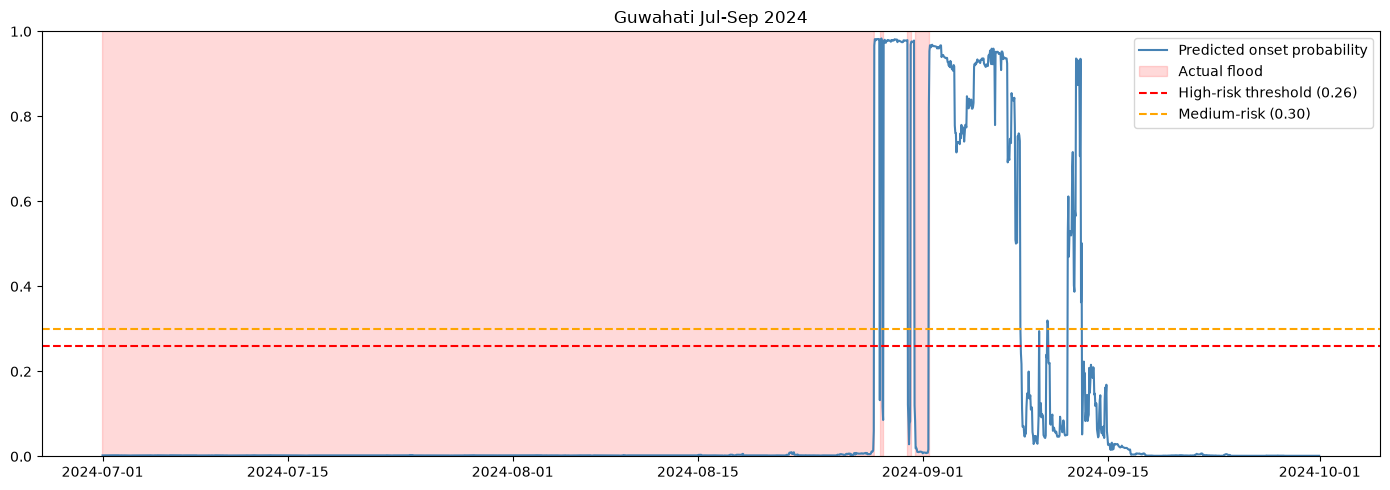

In [12]:
s = res[(res["station_id"] == "ASM_GW01") & (res["timestamp"] < "2024-10-01")]

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(s["timestamp"], s["probability"], label="Predicted onset probability", color="steelblue")
ax.fill_between(s["timestamp"], 0, 1, where=s["flood_occurred"] == 1, color="red", alpha=0.15, label="Actual flood")
ax.axhline(t_tuned, color="red", linestyle="--", label=f"High-risk threshold ({t_tuned:.2f})")
ax.axhline(0.3, color="orange", linestyle="--", label="Medium-risk (0.30)")
ax.set_ylim(0, 1)
ax.legend(loc="upper right")
ax.set_title("Guwahati Jul-Sep 2024")
plt.tight_layout()
plt.show()

In [13]:
joblib.dump({"model": xgb_tuned, "threshold": t_tuned, "features": features, "params": best_params},
            "../models/xgb_final_onset_24h.pkl")
tuning.to_csv("../models/xgb_tuning_results.csv", index=False)
print("Final model saved: models/xgb_final_onset_24h.pkl")

Final model saved: models/xgb_final_onset_24h.pkl
